<a href="https://colab.research.google.com/github/Jakub-Dufek/overtone-singing-analysis/blob/main/overtone_singing_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## **ISS individual project - overtone singing | Jakub Dufek**

You are currently sitting in a soundproof counterintelligence office in your role as an audio analyst. Your mission is to uncover acoustic anomalies, analyze suspicious signals, and identify hidden threats within them.

Your colleagues in the field have provided you with a recording intercepted directly from the internal PA system of a Western maximum-security prison, in which a hidden message is likely embedded. Incarcerated here is a charismatic Mongolian monk originally from the Tuvan borderlands. Under the principle of respecting religious freedoms, the prison administration permitted him to broadcast evening traditional prayers over the prison intercom to his fellow imprisoned countrymen. However, intelligence has uncovered that the monk is using this channel to coordinate a massive prison riot.

The intelligence team further discovered that the instructions for the riot are encoded using the harmonic frequencies of overtone (throat) singing. At half-second intervals, the monk alters his fundamental pitches while simultaneously using a specialized vocal technique to boost their 5th, 6th, or 7th harmonics. These boosted harmonics correspond to digital bits, which the monk combines to form ASCII characters, thereby briefing the other inmates on the details of the planned uprising. Characters are represented by 8 consecutive bits, transmitted most significant bit first (MSB first).

The code works as follows:
- The 5th harmonic represents a bit with a value of 0
- The 6th harmonic represents a bit with a value of 1
- The 7th harmonic represents the end of the message (STOP signal)
- The prison administration has implemented a security broadcast delay, providing sufficient time to process, alter, and subsequently air a sanitized version of the recording.


Your task is to build a program that will:
- Decrypt the original recording as well as any future recordings
- Prevent future recordings from using amplified harmonic frequencies as a data carrier, neutralizing the signal and leaving only the natural singing without the boosted overtones

In [35]:
  # Lib importing
from scipy.io import wavfile                                      # wav files
import matplotlib.pyplot as plt                                   # spectrogram
from IPython.display import Audio as interactive_audio_player     # audio player
import numpy as np

  # Data access
!git clone -q https://github.com/Jakub-Dufek/overtone-singing-analysis.git

First I'll showcase an example of one of my overtone singing recordings on a spectrogram, where we see the fifth harmonic clearly highlighted and enhanced

My entire project is based on this very principle

Sampling rate: 48000
Data shape: (240003,)
Data type: int16


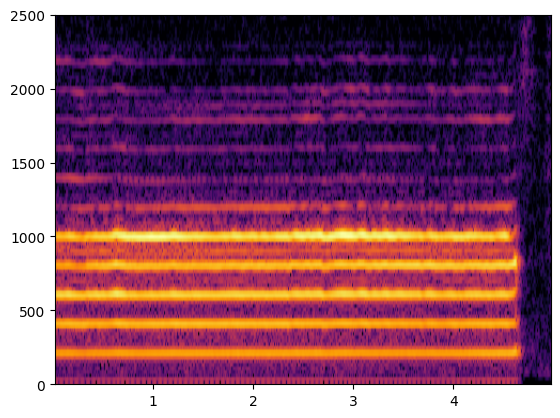

In [36]:
  # Data access
%cd -q overtone-singing-analysis
sampling_rate_hz, audio_samples = wavfile.read("data/raw/overtone_singing_showcase.wav")

  # Audio detail printing
print("Sampling rate:", sampling_rate_hz)
print("Data shape:", audio_samples.shape)
print("Data type:", audio_samples.dtype)

  # Spectrogram building
plt.specgram(
    x = audio_samples,      # "x" axis (time)
    Fs = sampling_rate_hz,  # "y" axis (signal frequency)
    noverlap = 1536,        # Makes spectrogram less pixely
    NFFT = 2048,            # Makes frequency lines sharp instead of blurry
    vmin = -25,             # Sets lowest signal strength worth tracking
    cmap = 'inferno')       # Highlights especially strong frequencies
plt.ylim(0, 2500)   # Capping max Fs
plt.show()

interactive_audio_player(data=audio_samples, rate=sampling_rate_hz)